## **Preparación examen claude architect (CCAR-F)**

# Día 3: Tool Design & MCP Integration (D2)

### Importaciones e instalación de dependencias

In [ ]:
# Importaciones

import sys
from pathlib import Path
import os
import time
import cliente_mcp_claude_dia3
import herramientas_dia3
import servidor_mcp_dia3

from anthropic import Anthropic

sys.path.insert(0, str(Path.cwd().parents[1]))
from src.config import ANTHROPIC_API_KEY, CLAUDE_MODEL, MAX_OUTPUT_TOKENS

In [2]:
# Buscar proyectos
resultado = herramientas_dia3.buscar_proyectos("videojuegos")
print(resultado)

# Obtener un proyecto por código
proyecto = herramientas_dia3.obtener_proyecto("G1")
print(proyecto)

# Calcular una media
media = herramientas_dia3.calcular_media([7, 8, 9])
print(media)

{'total': 1, 'resultados': [{'codigo': 'G1', 'titulo': 'EDA de videojuegos', 'estado': 'revision', 'nota': 8.5}]}
{'codigo': 'G1', 'titulo': 'EDA de videojuegos', 'estado': 'revision', 'nota': 8.5}
{'media': 8.0, 'cantidad': 3}


In [5]:

from cliente_mcp_claude_dia3 import ejecutar

resultado = await ejecutar(
    "Busca el proyecto de videojuegos, "
    "consulta su código exacto y dime su nota."
)

print(resultado)


[11/16/26 16:53:26] INFO     HTTP Request: POST https://api.anthropic.com/v1/messages "HTTP/1.1 200 ]8;id=3645535;file://c:\Users\rafae\Documents\GitHub\claude_architect\.venv\Lib\site-packages\httpx2\_client.py\_client.py]8;;\:]8;id=3645536;file://c:\Users\rafae\Documents\GitHub\claude_architect\.venv\Lib\site-packages\httpx2\_client.py#1917\1917]8;;\
                             OK"                                                                                   

Llamada 1 | stop_reason=tool_use


[11/16/26 16:53:28] INFO     HTTP Request: POST https://api.anthropic.com/v1/messages "HTTP/1.1 200 ]8;id=3645541;file://c:\Users\rafae\Documents\GitHub\claude_architect\.venv\Lib\site-packages\httpx2\_client.py\_client.py]8;;\:]8;id=3645542;file://c:\Users\rafae\Documents\GitHub\claude_architect\.venv\Lib\site-packages\httpx2\_client.py#1917\1917]8;;\
                             OK"                                                                                   

Llamada 2 | stop_reason=end_turn
{'estado': 'completado', 'respuesta': 'El proyecto de videojuegos es **"EDA de videojuegos"**, con código **G1**. Su nota es **8.5**, y su estado es "revisión".', 'llamadas': 2, 'tokens_entrada': 2087, 'tokens_salida': 277}


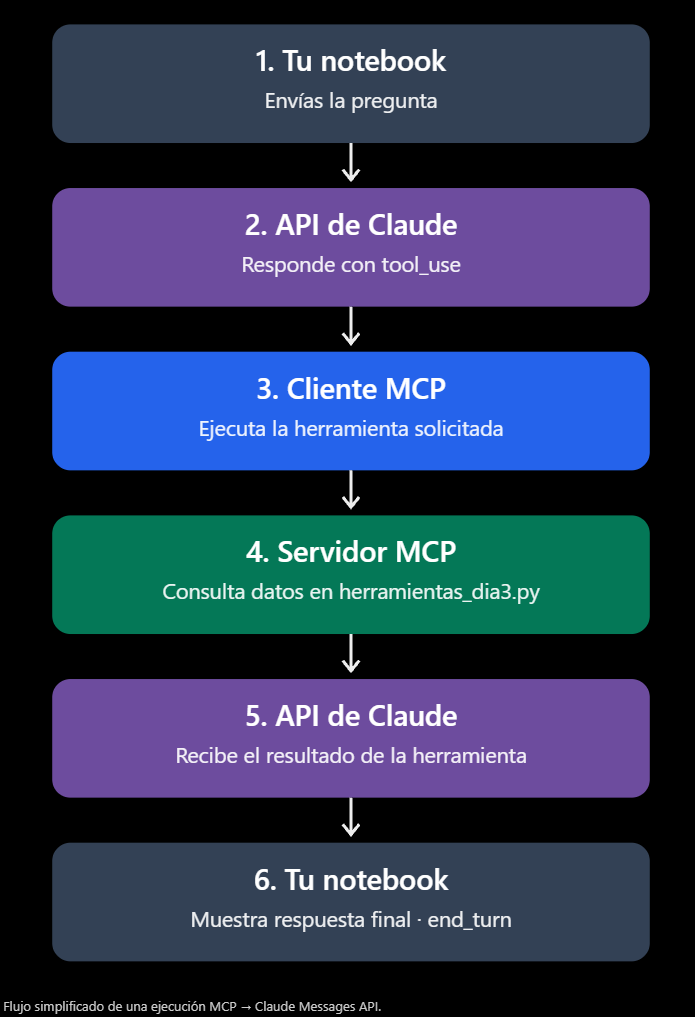

# CCAR-F — Día 3: Tool Design & MCP Integration

**Dominio:** D2 · Tool Design & MCP Integration (**18 %** del examen).  
**Duración:** 4 horas.  
**Prerequisitos:** Día 1 (Messages API), Día 2 (Agentic Loop y `tool_use`), Python intermedio.  
**Entorno:** Windows 11, VS Code, Git Bash, Python 3.12, `.venv` y API de Claude disponible.  
**Estado:** material de estudio propio, no preguntas oficiales.

> Tener una herramienta conectada no significa que el sistema sea seguro. La calidad de la selección, los contratos, los permisos y los fallos deben diseñarse explícitamente.

## Objetivos

- Diferenciar herramientas y funciones del cliente, MCP y herramientas integradas de Claude Code.
- Escribir descripciones y esquemas sin ambigüedades.
- Distinguir búsqueda vacía, error de validación, de permisos, de negocio y transitorio.
- Configurar `tool_choice` y asignar herramientas según la especialización.
- Comprender host, cliente, servidor MCP; tools, resources, prompts; stdio y Streamable HTTP.
- Crear un MCP server v2, probarlo localmente y utilizar un puente MCP→Messages API.
- Distinguir Read, Write, Edit, Bash, Grep y Glob en Claude Code.

## Programa (240 minutos)

| Tiempo | Módulo | Tema |
|---|---|---|
| 40 min | M1 | Diseño de herramientas |
| 35 min | M2 | Errores estructurados |
| 30 min | M3 | `tool_choice` y tool scoping |
| 70 min | M4 | Laboratorio MCP + Claude |
| 25 min | M5 | Integración con Claude Code |
| 40 min | M6 | Ejercicios, examen y soluciones |

---

# M1. Diseño de herramientas (40 min)

## 1.1. Por qué el nombre y la descripción son parte de la arquitectura

Las herramientas `analyze_content` y `analyze_document`, definidas ambas como «analiza información», son ambiguas. El modelo puede escoger la equivocada. Es preferible separar herramientas por intención:

- `buscar_proyectos(consulta, limite=5)`: descubre códigos por búsqueda textual. Éxito sin coincidencias: `resultados=[]`.
- `obtener_proyecto(codigo)`: recupera un proyecto por código exacto y falla si no existe.
- `calcular_media(notas)`: realiza exclusivamente el cálculo, no consulta bases de datos.

Una buena descripción explica propósito, cuándo se invoca, entradas con ejemplos, formato de salida, límites y qué hacer si no hay resultados. Debe decir también **cuándo no usarla** frente a una herramienta parecida.

## 1.2. JSON Schema y validación

```python
TOOLS = [{
    "name": "buscar_proyectos",
    "description": (
        "Busca por parte del título o código cuando desconoces el ID exacto. "
        "Devuelve {total, resultados}; sin coincidencias: []. "
        "Para un código conocido, utiliza obtener_proyecto."
    ),
    "input_schema": {
        "type": "object",
        "properties": {
            "consulta": {"type": "string", "minLength": 1},
            "limite": {"type": "integer", "minimum": 1, "maximum": 10}
        },
        "required": ["consulta"],
        "additionalProperties": False
    }
}]
```

En la Messages API, `strict: True` en una definición compatible puede garantizar entradas conformes al esquema de la herramienta. No garantiza la existencia del dato ni la autorización. Valida en tu backend de todas maneras.

### Ejercicio 1

Rediseña `analyze_content`, `analyze_document` y `search_data` como tres operaciones: buscar por título, consultar por código exacto y calcular una media. Especifica entradas, salida y errores.

---

# M2. Errores estructurados y recuperación (35 min)

## 2.1. Contrato de error

```json
{
  "ok": false,
  "errorCategory": "validation",
  "code": "INVALID_INPUT",
  "isRetryable": false,
  "message": "Se esperaba un código de proyecto no vacío."
}
```

Son campos **definidos por nuestra aplicación**, no campos obligatorios de MCP. MCP transmite errores de ejecución con `isError` (propiedad Python `is_error`).

| Caso | Tipo | Reintento idéntico |
|---|---|---|
| Consulta sin coincidencias | Éxito vacío | No hace falta |
| Timeout de API | Transitorio | Posible, con límite |
| Argumento inválido | Validación | No: corregir argumento |
| Acceso denegado | Permiso | No: revisar acceso |
| Regla de negocio | Business | No sin cambiar condiciones |

**Muy importante:** en el SDK MCP v2, si una herramienta *lanza una excepción ordinaria*, el SDK la comunica como resultado de herramienta con `is_error=True`. Una excepción de protocolo `MCPError` es diferente: no entrega un resultado normal de herramienta. No devuelvas errores como si fueran respuestas correctas.

Para operaciones con efectos secundarios, como cobros, revisa idempotencia, estado final y posibles duplicados **antes** de reintentar tras un timeout.

### Ejercicio 2

Clasifica: (1) búsqueda vacía válida, (2) timeout temporal, (3) nota 15, (4) consulta sin permisos, (5) devolución superior al máximo permitido. Justifica cuándo reintentar.

---

# M3. `tool_choice` y distribución de herramientas (30 min)

`tool_choice` de Messages API dispone de estos modos:

| Modo | Función |
|---|---|
| `{"type": "auto"}` | El modelo decide si llamar herramientas |
| `{"type": "none"}` | Deshabilita herramientas para esa llamada |
| `{"type": "any"}` | Fuerza usar alguna herramienta si lo admite el modelo/configuración |
| `{"type": "tool", "name": "..."}` | Fuerza una concreta si está permitido |

**Advertencia actual:** no todos los modelos y configuraciones admiten `any` o `tool`; algunos devuelven error 400. Consulta la documentación del modelo antes de emplearlo. Para la práctica usamos `auto` (compatible con nuestro ejercicio).

Distribuye las herramientas de acuerdo con las responsabilidades. Un agente que únicamente resume no necesita, por defecto, una herramienta que permita escribir archivos o emitir reembolsos. Limitar las herramientas reduce ambigüedad y superficie de riesgo.

La selección mediante prompt **no sustituye** autorización y validación del backend. Separa operaciones de lectura y escritura, y exige confirmación cuando haya impacto real.

### Ejercicio 3 — Tool choice y alcance de herramientas

**Apartado A — `tool_choice`.** Para cada escenario, elige el modo apropiado (`auto`, `none`, `any` o `tool`) y justifícalo:

1. Claude puede responder directamente o solicitar una calculadora, según lo necesite.
2. Un proceso exige que se invoque una herramienta concreta, usando un modelo/configuración compatible con uso forzado.
3. Una etapa debe generar texto sin solicitar herramientas.
4. Un alumno intenta invocar una herramienta exclusiva de administradores.
5. Un agente tiene herramientas de lectura y de modificación de notas: explica cómo restringirlas.

**Apartado B — Distribución de herramientas.** Tienes un coordinador, un agente de análisis de datos y otro de documentación. Reparte: `buscar_proyectos`, `obtener_proyecto`, `calcular_media`, `leer_readme`, `editar_archivo`, `emitir_reembolso`. Justifica cuáles **no** asignarías a cada uno. Elige las herramientas por principio de mínimo privilegio; no basta con `tool_choice` para autorizar operaciones.

---

# M4. Introducción y laboratorio MCP (70 min)

## 4.1. Qué es MCP

**Model Context Protocol** estandariza cómo una aplicación de IA conecta con servidores externos que exponen información y acciones. MCP no es un modelo ni sustituye el razonamiento de Claude.

```text
Usuario → Host (Claude Code / app Python)
                 ├─ Cliente MCP → Servidor MCP A (proyectos)
                 └─ Cliente MCP → Servidor MCP B (documentos)
```

- **Host:** aplicación que organiza la interacción con el modelo.
- **Cliente:** conexión del host con un servidor.
- **Servidor:** expone funcionalidades y contenido mediante el protocolo.

### Las tres primitivas MCP

| Primitiva | Uso | Ejemplo |
|---|---|---|
| Tool | Ejecuta una función | `obtener_proyecto("G1")` |
| Resource | Ofrece información contextual | `bootcamp://catalogo` |
| Prompt | Plantilla reutilizable | `analizar_proyecto(codigo)` |

### Transportes

- **stdio**: comunicación entre procesos locales por stdin/stdout. Evita escribir diagnósticos normales en stdout del servidor, porque interrumpirías el protocolo.
- **Streamable HTTP**: servidor accesible mediante HTTP. Requiere atención especial a autenticación y autorización en entornos remotos.

## 4.2. Entorno

Desde la raíz del repositorio en Git Bash:

```bash
source .venv/Scripts/activate
python -m pip install --upgrade 'mcp[cli]' anthropic
```

Se utiliza **MCP Python SDK v2**, cuya API de servidor es `from mcp.server import MCPServer`. Un tutorial anterior puede utilizar `FastMCP`; revisa la versión instalada y el tutorial correspondiente. No mezcles códigos v1/v2.

Crea una carpeta `Ckeckpoints/Dia3` y copia allí los cuatro archivos `.py` del ZIP. El cliente necesita que se ejecute desde una ubicación donde pueda importar el servidor.

## 4.3. Servidor MCP

Archivo: `servidor_mcp_dia3.py`.

```python
from mcp.server import MCPServer
from herramientas_dia3 import buscar_proyectos as buscar, obtener_proyecto as obtener

mcp = MCPServer("BootcampDemoD3")

@mcp.tool()
def buscar_proyectos(consulta: str, limite: int = 5) -> dict:
    """Busca por título o código; usar si no conocemos el ID exacto. Devuelve total y resultados."""
    return buscar(consulta, limite)

@mcp.tool()
def obtener_proyecto(codigo: str) -> dict:
    """Recupera exclusivamente por código exacto (G1, G2...). No sirve para búsqueda textual."""
    return obtener(codigo)

@mcp.resource("bootcamp://catalogo")
def catalogo() -> str:
    """Devuelve los códigos del catálogo ficticio."""
    return "G1, G2, G3"

@mcp.prompt()
def analizar_proyecto(codigo: str) -> str:
    """Plantilla de estudio para evaluar un proyecto."""
    return f"Consulta {codigo} y resume título, estado y nota usando las herramientas."
```

**El ZIP incluye la versión completa** con `calcular_media`, docstrings explicativas y datos ficticios. El SDK deriva los esquemas de los type hints y descripciones de las docstrings.

## 4.4. Inspector MCP sin API de Claude

```bash
mcp dev servidor_mcp_dia3.py
```

El comando de desarrollo requiere que esté disponible Node.js / `npx`. Abre la dirección que aparezca en la terminal y prueba:

1. `buscar_proyectos` con `consulta="videojuegos"`.
2. `buscar_proyectos` con una consulta sin coincidencias.
3. `obtener_proyecto` con `codigo="G1"`.
4. `obtener_proyecto` con `codigo="G999"`: comprueba `isError`.
5. Resource `bootcamp://catalogo` y prompt `analizar_proyecto`.

Si no tienes Node.js, puedes utilizar un cliente MCP en Python; las pruebas unitarias locales no necesitan Inspector.

## 4.5. MCP + Claude API real

Archivo: `cliente_mcp_claude_dia3.py`. Este cliente, en el mismo proceso, hace cuatro cosas:

1. Se conecta al servidor MCP utilizando `async with Client(mcp)`.
2. Descubre herramientas por `await conexion.list_tools()` y convierte sus esquemas a `tools=` de Messages API.
3. Envía preguntas a Claude y recibe `tool_use`.
4. Ejecuta `await conexion.call_tool(...)`, convierte `CallToolResult` a `tool_result`, mantiene IDs e historial, y continúa hasta `end_turn` o un límite.

Fragmento central:

```python
async with Client(mcp) as conexion:
    disponibles = await conexion.list_tools()
    tools = [
        {"name": t.name, "description": t.description or t.name,
         "input_schema": t.input_schema}
        for t in disponibles.tools
    ]
    # Aquí se llama a Anthropic y se ejecuta el Agentic Loop.
```

La implementación completa está en el ZIP. Por prudencia no ejecutamos la API durante las pruebas automatizadas. **La existencia de 5 USD no significa que Claude Code esté necesariamente habilitado por esa facturación; esta práctica utiliza la Anthropic Messages API.**

Configura tu clave en Git Bash sin incluirla en el código:

```bash
read -rs -p 'Anthropic API Key: ' ANTHROPIC_API_KEY
echo
export ANTHROPIC_API_KEY
```

Ejecuta, solo cuando quieras consumir API:

```bash
python cliente_mcp_claude_dia3.py
```

Las herramientas y datos de ejemplo son ficticios; ninguna operación escribe archivos ni datos de alumnos. Si el modelo no existe en tu cuenta, ajusta `ANTHROPIC_MODEL` a uno disponible.

### Ejercicio 4 — MCP: teoría y práctica

**Apartado A — Conceptos:**

1. Diferencia host, cliente y servidor MCP.
2. ¿Qué diferencia hay entre una tool y un resource?
3. ¿Para qué sirve un prompt MCP?
4. ¿Qué transporte usarías con un servidor local invocado por Claude Code?
5. ¿Qué devuelve una búsqueda válida sin coincidencias?
6. ¿Qué indica `is_error=True` en un resultado MCP?
7. ¿MCP sustituye la API de Claude o los controles de autorización del backend?

**Apartado B — Implementación:** Añade `contar_proyectos_por_estado(estado)` con retorno estructurado, docstring y validación. Comprueba que el servidor la descubre y que las pruebas pueden ejecutarla sin Claude. Si lo deseas, repite después con la API para observar la selección del modelo.

---

# M5. MCP en Claude Code y herramientas integradas (25 min)

## 5.1. Alcance de configuración

| Alcance | Ubicación | Compartido |
|---|---|---|
| Local | `~/.claude.json` bajo el proyecto | No |
| Proyecto | `.mcp.json` en la raíz | Sí, por Git |
| Usuario | `~/.claude.json` | No, en varios proyectos |

Ejemplo de `.mcp.json` en la raíz de tu repositorio (**adapta el intérprete a tu venv**):

```json
{
  "mcpServers": {
    "bootcamp-demo": {
      "type": "stdio",
      "command": "python",
      "args": ["Ckeckpoints/Dia3/servidor_mcp_dia3.py"]
    }
  }
}
```

El servidor necesita que el Python llamado tenga `mcp` instalado. Al usar Claude Code, revisa la confianza en el repositorio y autoriza el servidor solo si reconoces su código. No subas claves en el JSON; utiliza variables de entorno, tokens de alcance mínimo y mecanismos de autenticación seguros.

**Importante:** un script con `print()` en stdout durante el modo stdio puede romper los mensajes del protocolo. Los logs del servidor van a stderr.

## 5.2. Herramientas integradas de Claude Code

| Herramienta | Utilidad |
|---|---|
| `Glob` | Localizar rutas por patrón (`**/*.py`) |
| `Grep` | Buscar contenido en archivos (`def entrenar`) |
| `Read` | Leer un archivo |
| `Write` | Crear o reemplazar contenido completo |
| `Edit` | Cambiar un fragmento concreto si el ancla es única |
| `Bash` | Ejecutar comandos, tests, scripts |

No confundas `Glob` (nombres/rutas) con `Grep` (contenido). Antes de editar código, busca archivos con `Glob`, localiza símbolos con `Grep` y usa `Read` para inspeccionar el contexto. Si `Edit` no encuentra una coincidencia única, revisa el archivo y emplea una alternativa controlada. Para ejecutar pruebas utiliza `Bash` en un entorno confiable.

### Ejercicio 5

El usuario pide «Encuentra los archivos Python que definen `extract_text`, revisa la función, corrige una línea y ejecuta tests». Selecciona y ordena las herramientas correctas y explica riesgos de seguridad o pérdida de datos.

---

# M6. Evaluación de Día 3 (40 min)

**100 puntos; diseñada para practicar, no es un examen oficial.**

## Parte A. 10 preguntas tipo test (40 puntos)

1. Dos herramientas tienen nombres parecidos y descripciones vagas. ¿Qué corregir primero?
   - A. Añadir más herramientas. B. Diferenciar propósitos, descripciones y contratos. C. Forzar siempre una. D. Borrar el system prompt.
2. ¿Cuál es la finalidad de `input_schema`?
   - A. Definir argumentos esperados. B. Autenticar al usuario. C. Guardar historial. D. Fijar precio del modelo.
3. Una búsqueda devuelve `[]` sin errores. ¿Qué es?
   - A. Timeout. B. Acceso denegado. C. Éxito sin coincidencias. D. Error de protocolo.
4. ¿Qué error suele ser reintentable sin cambiar argumentos?
   - A. Permiso denegado. B. Nota fuera de rango. C. Timeout transitorio. D. Política de reembolsos.
5. ¿Qué modo permite que Claude elija si usar herramientas?
   - A. `none`. B. `auto`. C. `any`. D. `tool`.
6. ¿Quién mantiene la conexión del host con un servidor MCP?
   - A. La API key. B. La resource. C. El cliente MCP. D. El prompt.
7. ¿Cuál es un resource MCP?
   - A. Un catálogo de datos expuesto mediante una URI para que el host lo consulte. B. Una función que modifica la base. C. Una llamada obligatoria. D. Una API key.
8. ¿Dónde compartir la configuración MCP específica de un proyecto Claude Code?
   - A. Un `.env` público. B. `.mcp.json` en la raíz del proyecto. C. El token en README. D. `requirements.txt`.
9. ¿Qué herramienta encuentra rutas `**/*.py`?
   - A. Read. B. Write. C. Grep. D. Glob.
10. Una herramienta MCP lanza una excepción ordinaria durante su ejecución. ¿Qué recibe normalmente el **cliente MCP**?
   - A. Éxito confirmado. B. Un resultado de herramienta con `is_error=True` (campo `isError` del protocolo). C. Siempre `end_turn`. D. Un nuevo usuario autenticado.

## Parte B. Razonamiento técnico (30 puntos)

**B1 (10 puntos).** Explica una descripción eficaz de herramienta frente a otra ambigua. Incluye propósito, ejemplos, límites, entrada y salida.

**B2 (10 puntos).** Diferencia un resultado vacío válido, un error transitorio y un error de permisos. Propón el comportamiento de recuperación para cada uno.

**B3 (10 puntos).** Distingue `tool_choice` `auto`, `none`, `any`, `tool` e indica una restricción actual que deba verificarse antes de usar forced tool use.

## Parte C. Escenario arquitectónico (20 puntos)

Un bootcamp conecta su plataforma de proyectos a Claude por MCP. Profesores deben consultar proyectos autorizados, alumnos solo pueden consultar los suyos y ciertos coordinadores pueden crear evaluaciones. Diseña tools/resources/prompts, esquema de permisos, ámbitos de configuración, errores, reintentos, control de costes y seguimiento de resultados.

## Parte D. Python (10 puntos)

Escribe una función `procesar_resultado_mcp(result)` que lea `result.is_error`, utilice `result.structured_content` si existe y la operación tuvo éxito, o recorra únicamente bloques de texto del resultado para crear una cadena. Debe devolver `{"ok": bool, "contenido": ...}` sin acceder a `.text` en bloques de otros tipos.

---

# Solucionario de ejercicios

### Ejercicio 1

Diseñar tres operaciones separadas: `buscar_proyectos(consulta: str, limite: int=5)` devuelve `{total, resultados}` con `[]` válido; `obtener_proyecto(codigo: str)` devuelve objeto exacto o fallo; `calcular_media(notas: list[float])` devuelve `{media, cantidad}` y rechaza vacío/no numérico/fuera de rango. Describir cuándo usar una frente a las otras.

### Ejercicio 2

1. Búsqueda vacía: éxito con lista vacía, sin reintento obligatorio. 2. Timeout: transitorio, puede reintentarse con límite/backoff e idempotencia comprobada. 3. Nota 15: validación, corregir argumento. 4. Datos de otro usuario: permission, denegar sin filtrar datos. 5. Devolución excesiva: business, explicar límite y escalar si procede; no reintentar idéntico.

### Ejercicio 3 — Respuestas de ambos apartados

**Apartado A — `tool_choice`:**

1. `auto`: Claude decide si necesita calculadora.
2. `tool` con nombre específico, **solo** si el modelo y su configuración admiten uso forzado; `any` obliga a alguna, pero no a una específica.
3. `none`: no se permiten solicitudes de herramienta.
4. No exponer una herramienta administrativa al alumno y, sobre todo, denegar su ejecución en el backend si no está autorizado. `tool_choice` por sí solo no verifica permisos.
5. Separar herramientas de lectura y escritura; exponer las de escritura solo a roles autorizados, validar cada llamada y exigir confirmación humana para cambios sensibles cuando corresponda.

**Apartado B — Distribución:**

- **Análisis de datos:** `buscar_proyectos`, `obtener_proyecto`, `calcular_media`. No necesita `editar_archivo` ni `emitir_reembolso`.
- **Documentación:** `leer_readme` y, si está expresamente autorizado, `editar_archivo` restringido a documentos aprobados. No necesita `emitir_reembolso` ni acceso general de lectura de proyectos.
- **Coordinador:** delega y agrega resultados; únicamente se le conceden capacidades adicionales indispensables. No necesita `emitir_reembolso` para estas tareas.

El principio rector es **mínimo privilegio**; el backend debe validar todas las operaciones y no confiar en la selección del modelo.

### Ejercicio 4 — Respuestas de ambos apartados

**Apartado A — Conceptos:**

1. Host: aplicación que organiza la interacción con el modelo; cliente: componente que comunica al host con un servidor MCP; servidor: expone herramientas, recursos y prompts.
2. Tool: ejecuta una operación; resource: proporciona información identificable mediante URI.
3. Prompt: plantilla reutilizable para configurar o iniciar una tarea.
4. `stdio` para un servidor local ejecutado como subproceso.
5. Una respuesta válida, por ejemplo `{total: 0, resultados: []}`, con `is_error=False`.
6. `is_error=True` indica que la operación MCP falló; el cliente recibe un resultado fallido, no un éxito vacío.
7. MCP no sustituye a la Messages API ni a la autenticación/autorización del backend.

**Apartado B — Solución Python completa:**

En `herramientas_dia3.py`:

```python
def contar_proyectos_por_estado(estado: str) -> dict:
    """Cuenta proyectos de un estado válido; no modifica datos."""
    estados_validos = {p["estado"] for p in PROYECTOS.values()}
    if not isinstance(estado, str) or estado not in estados_validos:
        raise ValueError(f"Estado no válido. Opciones: {sorted(estados_validos)}")
    total = sum(p["estado"] == estado for p in PROYECTOS.values())
    return {"estado": estado, "total": total}
```

En `servidor_mcp_dia3.py`, añade el import y registra la función:

```python
from herramientas_dia3 import contar_proyectos_por_estado as contar_local

@mcp.tool()
def contar_proyectos_por_estado(estado: str) -> dict:
    """Cuenta los proyectos de un estado exacto: revision, completado o pendiente."""
    return contar_local(estado)
```

Añade estas pruebas a `test_dia3.py`:

```python
from herramientas_dia3 import contar_proyectos_por_estado

# Dentro de la clase TestDia3:
def test_contar_revision(self):
    self.assertEqual(
        contar_proyectos_por_estado("revision"),
        {"estado": "revision", "total": 1}
    )

def test_contar_estado_invalido(self):
    with self.assertRaises(ValueError):
        contar_proyectos_por_estado("cerrado")
```

Verifica el descubrimiento de la nueva herramienta usando MCP Inspector o `list_tools()` del cliente; después, si quieres, prueba Claude con la API. Esta ampliación no se inserta automáticamente en los archivos Python originales para conservar el ejercicio sin resolver en ellos.

### Ejercicio 5

`Glob` para encontrar archivos `.py`; `Grep` para localizar `def extract_text`; `Read` para entender el archivo; `Edit` para cambio localizado tras comprobar la coincidencia; `Bash` para ejecutar tests en entorno controlado. Evitar `Write` completo si solo hay un cambio preciso, y evitar ejecutar comandos arbitrarios de fuentes no confiables.

---

# Solucionario de evaluación

## Parte A — Respuestas y explicación

| # | Respuesta | Razón |
|---|---|---|
| 1 | B | Primero reparar ambigüedades entre herramientas. |
| 2 | A | `input_schema` define argumentos. |
| 3 | C | Una búsqueda sin coincidencias es éxito válido. |
| 4 | C | Timeout transitorio puede ser reintentable. |
| 5 | B | `auto` deja a Claude elegir. |
| 6 | C | El cliente MCP mantiene conexión con servidor. |
| 7 | A | Resource expone datos de contexto mediante URI. |
| 8 | B | `.mcp.json` es la configuración compartible del proyecto. |
| 9 | D | Glob busca rutas por patrones. |
| 10 | B | El cliente MCP recibe un resultado fallido (`is_error=True` en Python). |

## Parte B — Respuestas modelo

**B1:** Una buena interfaz distingue `buscar_proyectos` para búsqueda por fragmentos y `obtener_proyecto` para búsqueda por código exacto. La descripción explica qué caso activa cada función, argumentos con ejemplos, la forma del resultado y qué ocurre si no hay coincidencias. El esquema evita formatos inesperados y el backend valida permisos y reglas de negocio. Un nombre genérico como `analyze_content` puede confundir al modelo.

**B2:** Consulta exitosa sin filas: `{ok:true,resultados:[]}`. Timeout temporal: error transitorio y `isRetryable:true`, con límites/backoff y comprobación de efectos secundarios. Acceso denegado: error de permiso, `isRetryable:false`; no se deben exponer datos ni repetir automáticamente. `isError` de MCP indica si la *ejecución de la herramienta* falló; los metadatos son un contrato de la aplicación.

**B3:** `auto`: Claude decide. `none`: sin herramientas. `any`: alguna herramienta obligatoria cuando el modelo lo admite. `tool`: herramienta concreta obligatoria cuando se admite. Algunos modelos/configuraciones recientes rechazan forced tool use y exigen `auto`, por lo que hay que verificar documentación del modelo. Usar forced tool use no reemplaza la autorización backend.

## Parte C — Arquitectura modelo

1. El frontend inicia el flujo de acceso y presenta la sesión o credencial; **no decide por sí mismo quién está autenticado**.
2. El backend valida la identidad mediante un proveedor/mecanismo confiable y comprueba permisos de profesor, alumno o coordinador antes de exponer datos.
3. Servidor MCP expone herramientas de lectura por ID y búsqueda de proyectos (scoped), un recurso de catálogo autorizado y un prompt plantilla para resumir evaluaciones. No expone datos no autorizados como recursos generales.
4. Para crear evaluaciones, otra herramienta con permisos de escritura, confirmación y trazabilidad, separada de lectura.
5. Claude recibe únicamente las herramientas y recursos aplicables al rol; el backend vuelve a autorizar cada llamada.
6. La aplicación diferencia vacío válido, error temporal, validación, permisos y negocio con mensajes y metadatos, reintentando solo operaciones idempotentes cuando procede.
7. Registra IDs y estado de ejecuciones, tokens, duración, errores y decisiones de permisos, sin almacenar credenciales o datos privados innecesarios.
8. Configuración compartida en `.mcp.json`; credenciales secretas por entorno o gestor de secretos; para experimentos personales, ámbito local/usuario.
9. El sistema no marca éxito por alcanzar un límite: exige conclusión verificable, datos autorizados y operaciones pendientes resueltas.

**Rúbrica (20):** componentes y flujo (5), MCP primitives y herramientas (5), seguridad (5), errores/costos/observabilidad (5).

## Parte D — Solución Python

```python
import json


def procesar_resultado_mcp(result) -> dict:
    """Convierte CallToolResult de MCP en datos para nuestra aplicación."""
    if not result.is_error and result.structured_content is not None:
        contenido = result.structured_content
    else:
        # MCP content puede contener texto, imágenes u otros bloques.
        textos = [block.text for block in result.content if block.type == "text"]
        contenido = "\n".join(textos)
    return {"ok": not bool(result.is_error), "contenido": contenido}
```

**Rúbrica (10):** reconoce `is_error` (2); usa `structured_content` solo en éxito (3); filtra bloques no textuales (3); estructura coherente (2).

---

# CHECKPOINT 03

```markdown
# CHECKPOINT 03 — Tool Design y MCP

**Dominio:** D2 · Tool Design & MCP Integration (18%)
**Día:** 3/8
**Estado:** En progreso

## Diseño
- [ ] Sé explicar por qué una descripción ambigua perjudica la selección.
- [ ] Diferencio búsqueda textual y consulta exacta.
- [ ] Construyo esquemas claros y valido argumentos.
- [ ] Comprendo strict tool use y sus límites.

## Errores y recuperación
- [ ] Diferencio éxito vacío, transitorio, validación, permisos y negocio.
- [ ] Utilizo `isError`/`is_error` correctamente.
- [ ] Evito reintentos peligrosos en operaciones con efectos secundarios.

## MCP
- [ ] Comprendo host, cliente y servidor.
- [ ] Distingo tools, resources y prompts.
- [ ] Sé cuándo elegir stdio o Streamable HTTP.
- [ ] He probado el servidor MCP local.
- [ ] He descubierto y ejecutado herramientas mediante un cliente MCP.
- [ ] He probado el bridge MCP → Claude API.

## Claude Code
- [ ] Distingo ámbitos local, proyecto y usuario.
- [ ] Sé usar Glob, Grep, Read, Edit, Write y Bash.

## Evaluación
Parte A: ___ / 40
Parte B: ___ / 30
Parte C: ___ / 20
Parte D: ___ / 10
**TOTAL: ___ / 100**
Errores y dudas pendientes:
1.
2.
3.
```

**Objetivo personal de estudio:** 85/100, no una puntuación oficial de aprobación. D2 continúa después de este checkpoint.

## Fuentes oficiales para consulta

- Certificación: https://anthropic-partners.skilljar.com/claude-certified-architect-foundations-certification
- Tool use y `tool_choice`: https://platform.claude.com/docs/en/agents-and-tools/tool-use/define-tools
- SDK MCP Python v2: https://py.sdk.modelcontextprotocol.io/
- MCP arquitectura: https://modelcontextprotocol.io/docs/learn/architecture
- Claude Code MCP: https://code.claude.com/docs/en/mcp

**Observación sobre las pruebas:** se han comprobado 18 pruebas unitarias de la lógica Python pura, sin consumir API. El SDK MCP v2 y la integración real con Claude no pueden ejecutarse en este entorno de preparación (instalación de dependencias externa no disponible). Sus ejemplos están basados en la documentación actual y requieren validación en tu ordenador.
